# KV cache: đo sự đánh đổi giữa tính lại và lưu K/V

## Mục tiêu và giả thuyết
Cache giữ K/V của prefix để decode không cần tính lại toàn bộ prefix; đổi lại nó dùng thêm bộ nhớ và prefill vẫn cần xử lý toàn bộ prompt. Với mô hình nhỏ chưa huấn luyện, chi phí Python/kernel launch có thể che khuất phần tính toán tiết kiệm, nên cache không được giả định trước là nhanh hơn.

Notebook chạy đúng hai wrapper generation công khai sau khi kiểm tra logits, đồng thời đo controlled replay có continuation IDs giống nhau. Các kết quả là cơ chế suy luận trên trọng số khởi tạo, không đo chất lượng ngôn ngữ hoặc hiệu năng production. Không có bước cài dependency.

In [ ]:
"""Tìm repository root, nạp API và công khai cấu hình thí nghiệm."""
import json
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'llm_foundations' / 'experiments' / 'kv_cache_benchmark.py').exists()), None)
if ROOT is None:
    candidate = Path('../..').resolve()
    if (candidate / 'llm_foundations' / 'experiments' / 'kv_cache_benchmark.py').exists(): ROOT = candidate
if ROOT is None: raise RuntimeError('Run notebook from repository root or experiments directory')
sys.path.insert(0, str(ROOT))
from llm_foundations.experiments.kv_cache_benchmark import (
    BenchmarkConfig,
    plot_results,
    run_benchmark,
    save_results,
)

config = BenchmarkConfig()
print('Repository:', ROOT)
print('Config:', json.dumps(config.__dict__, default=lambda x: x.__dict__, indent=2))
print('CUDA available:', __import__('torch').cuda.is_available())

Repository: /home/coronny/rag-project
Config: {
  "model": {
    "vocab_size": 128,
    "max_seq_len": 256,
    "d_model": 64,
    "num_layers": 2,
    "num_heads": 2,
    "d_k": 16,
    "d_v": 24,
    "d_ff": 128,
    "eps": 1e-05
  },
  "seed": 20261023,
  "dtype": "float32",
  "device": "auto",
  "warmup": 2,
  "repeats": 7,
  "prompt_lengths": [
    8,
    32,
    96
  ],
  "generated_tokens": 16,
  "generation_lengths": [
    1,
    8,
    32
  ],
  "generation_prompt_length": 32,
  "atol": 1e-05,
  "rtol": 0.0001
}
CUDA available: True


## Ranh giới đo

Mỗi workload so sánh cùng prompt, token budget, model weights và dtype. Correctness gate chạy trước thời gian; phase timing ở `eval()`/`no_grad()`, có CUDA synchronization ở biên interval. Decode cache được tạo trước khi bắt đầu đo D bước. Wrapper timing vẫn gọi nguyên wrapper để giữ nguyên xử lý mode, selector và nối token. Bộ nhớ CUDA chạy riêng từng arm, chỉ để một mô hình trên GPU, và peak allocated không cộng thêm KV payload. Quantile p25/p75 dùng nội suy tuyến tính tại `(n-1)*p`.

## Cách đọc các metric

Với prompt dài P, budget B và capacity M: `N=min(B, M-P)` là số token thực sinh, `D=max(N-1, 0)` là số decode sau prefill, và cache cuối có chiều dài `T=P+D`.

| Metric | Câu hỏi | Công thức / đơn vị | Đo gì, bỏ gì | Cách đọc |
|---|---|---|---|---|
| Logit max error / allclose | Hai đường tính có cho logits tương đương? | `max(abs(logits_ref-logits_cache))`; allclose dùng `atol`, `rtol` | So logits prefill và từng token decode; không phải timing | Error nhỏ và allclose=True cho phép diễn giải timing; đây không phải chất lượng ngôn ngữ |
| Prefill | Bao lâu để xử lý prompt? | Thời gian mỗi prompt call, ms | Uncached: full prompt forward; cached: logits và K/V cache; selector bị loại | Cache không bỏ chi phí đọc toàn prompt |
| Controlled decode | Bao lâu mỗi bước trên history được giữ cố định? | `decode_total_ms / D`, ms/step | Đo D bước replay trên cùng continuation IDs; chuẩn bị prompt/cache ban đầu ở ngoài interval | Là trung bình qua các context length; N=1 thì D=0 và metric là N/A, không phải 0 |
| Real-wrapper generation | Người gọi thực tế chờ bao lâu? | Wall time mỗi wrapper, ms | Gọi wrapper công khai; gồm selector, append và xử lý mode, bỏ prompt clone ngoài interval | Đây là end-to-end generation của workload, không cộng với phase timings |
| Tokens/s | Tốc độ sinh quan sát được? | `N / (generation_ms / 1000)`, tokens/s | Dùng chính wall time wrapper và N thực sinh | N=0 thì không xác định; không dùng budget thay N khi bị capacity truncate |
| Speedup | Arm nào nhanh hơn cùng workload? | `median(uncached) / median(cached)`, ratio-of-medians | Chia median cùng metric/case; không chia các quartile | >1 nghiêng về cache, <1 nghiêng về uncached; không hàm ý mọi prompt đều vậy |
| K/V MiB | Cache payload logic lớn bao nhiêu? | `sum(numel * element_size) / 2^20`, MiB tại T=P+D | Chỉ tensor K/V; không gồm allocator/workspace/model | Mức tăng theo context là payload, không phải toàn bộ VRAM |
| CUDA peak / delta | Bao nhiêu tensor memory được allocator giữ? | `peak_allocated_mib`; delta=`peak-baseline`, MiB | Pass riêng từng arm; peak trong wrapper generation, baseline gồm mô hình+prompt và pre-model allocated footprint | Không cộng K/V MiB vào peak. Footprint pre-model đo được là 8.125 MiB; được ghi trong baseline, không quy nó cho K/V |

## Quy trình đo và giới hạn thống kê

1. Sao chép trọng số theo role, đối chiếu parameter mapping, rồi chặn benchmark nếu logits không allclose.
2. Dùng cùng IDs/history cho controlled replay; warm up từng arm/workload và tạo cache mới cho mỗi repetition.
3. Đồng bộ CUDA ngay trước/sau interval; không đồng bộ từng token trong phase loop. Đo controlled prefill/decode riêng khỏi wrapper generation.
4. Lặp lại, luân phiên arm order và báo median cùng p25-p75; đây là độ phân tán quan sát trong các lần lặp, **không phải khoảng tin cậy**. Ứng với 7 lần đo, median mỗi lần đo cùng cấu hình sẽ được đánh dấu chấm trên line 
5. Đo memory ở pass tách biệt, chỉ một arm trên GPU; ghi pre-model, baseline, peak và delta để thấy phần footprint đã tồn tại trước model.

`config.seed` tạo input token IDs; seed khởi tạo model là metadata riêng `weight_seed` (cố định 20261023), không phải `config.seed`. Trọng số hai kiến trúc được copy/match trực tiếp, không dựa vào seed giống nhau.

Run: /home/coronny/rag-project/llm_foundations/experiments/kv_cache_benchmark_runs/20261023T112225Z_9ed22424
Device: cuda:0 | GPU: NVIDIA GeForce RTX 3060
Warmup/repeats: 2 / 7
Parameter mapping count: 35 | correctness: True
Source revision and hashes: {
  "revision": "3d83dce8ec14175616080f635e6663cc8f7aacb6",
  "sha256": {
    "llm_foundations/experiments/kv_cache_benchmark.py": "7f21a4f818b432245363ef0fdf613dcd1f1a1ccd4058318603845b480b121a85",
    "llm_foundations/experiments/test_kv_cache_benchmark.py": "577c2c082695ed658a4b4dc6b5766d6e32b7b185e74bf3889412ab1b455770e0",
    "llm_foundations/experiments/kv_cache_benchmark.ipynb": "c96c66868ba4bbc487be4f8913de0c98119fb2bb4ecee1db4248eb17c9687478",
    "llm_foundations/decoder_only_lm.py": "39cd078f9b50a1aa71da3f0e001652e76777ebdf16f3b66287b64f22dc467ff0",
    "llm_foundations/kv_cache/decoder_only_lm.py": "64533b4900c0dcc5168399b83ed088e6d6ef332d8a3d88c7312944ea6a476e6f",
    "llm_foundations/generation.py": "6e6ac23a727c9f0648b95b9

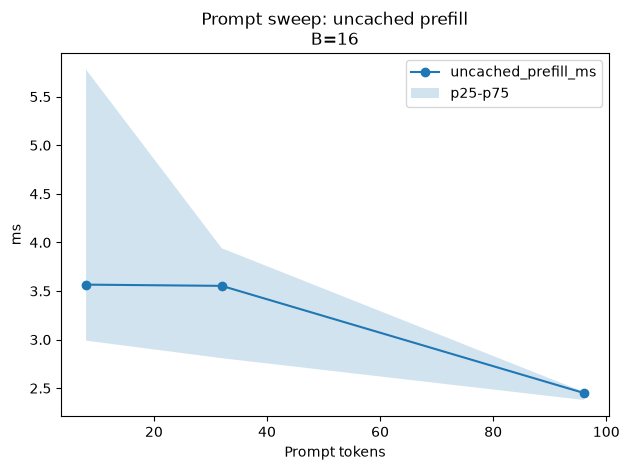

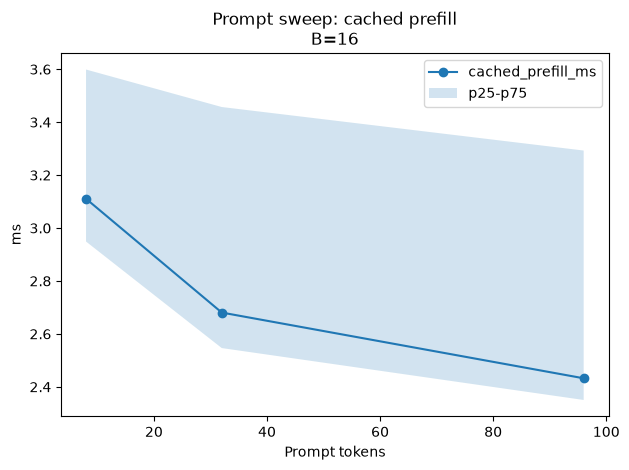

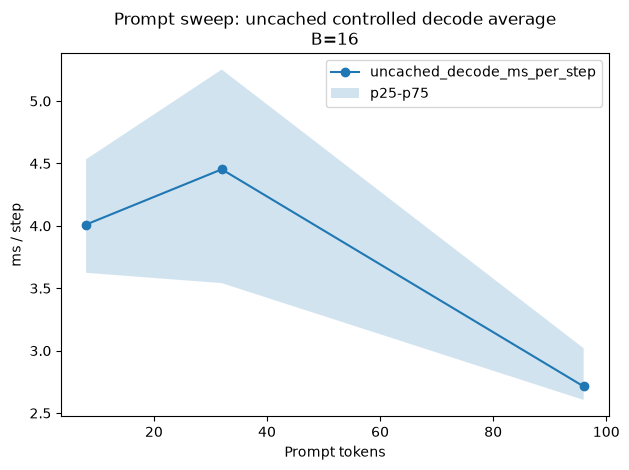

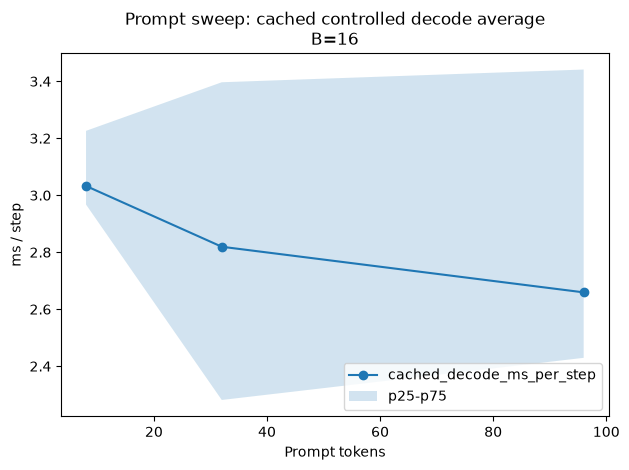

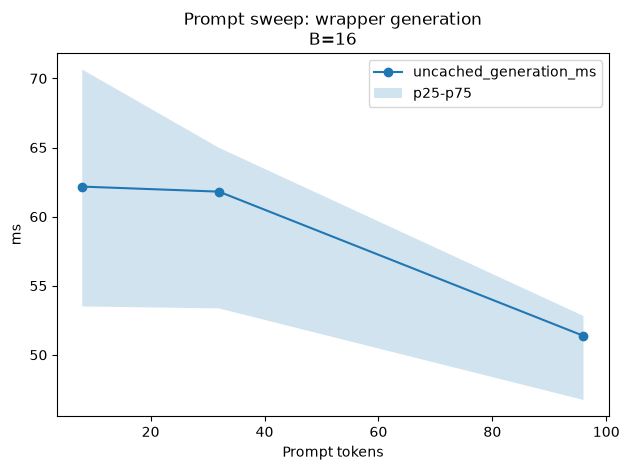

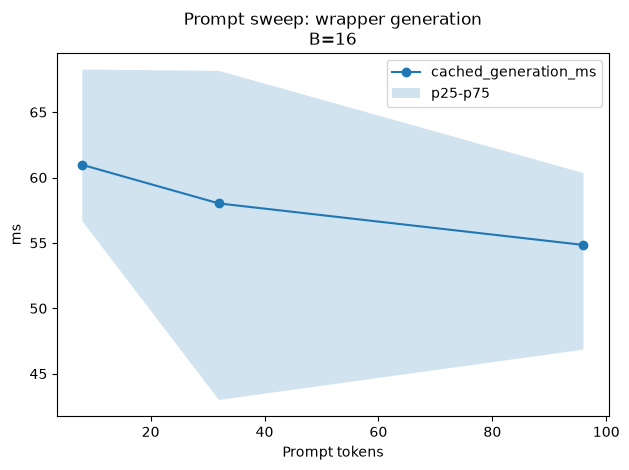

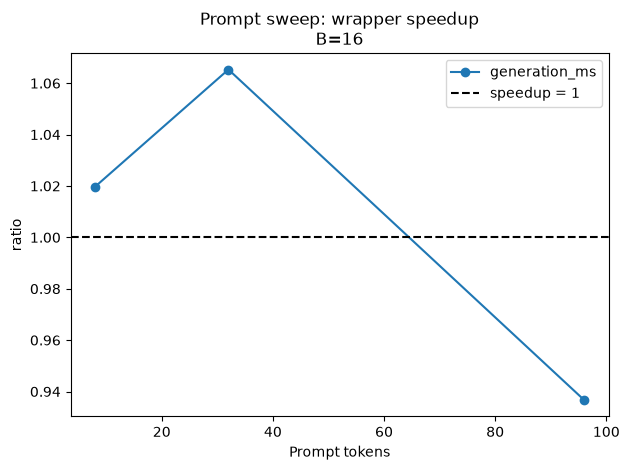

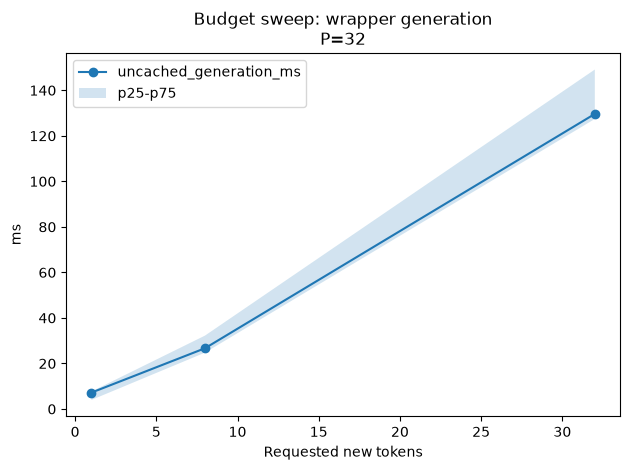

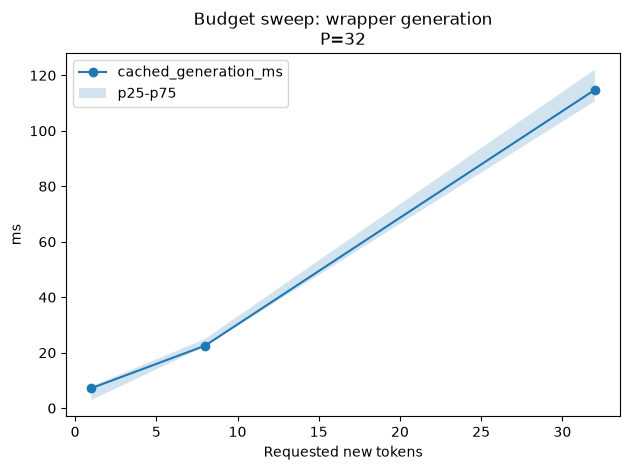

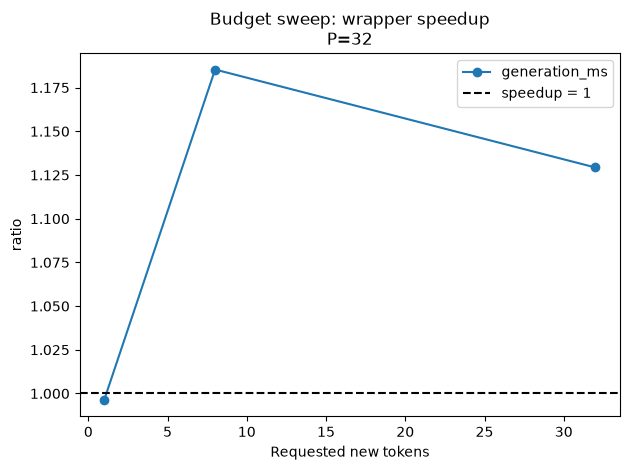

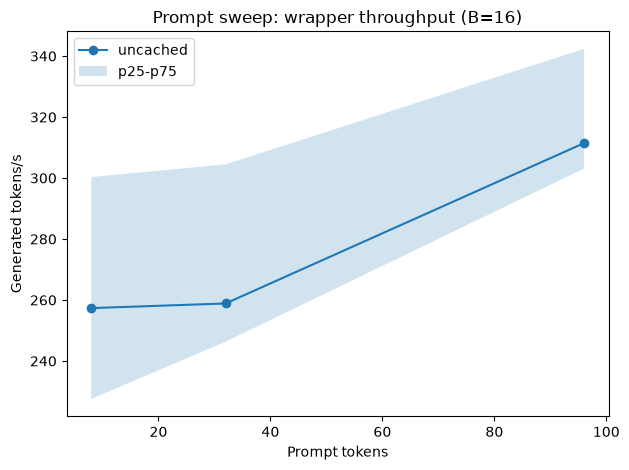

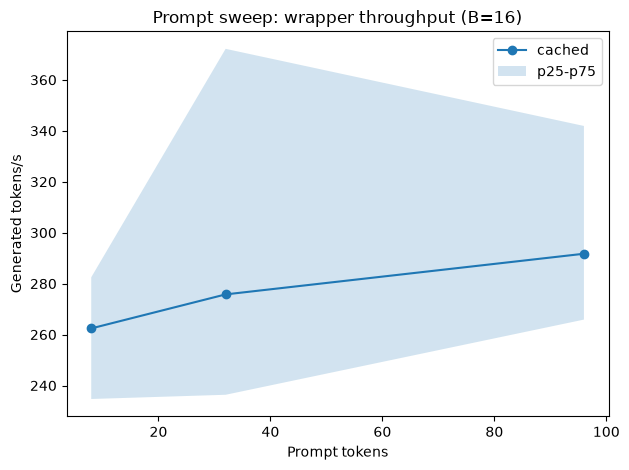

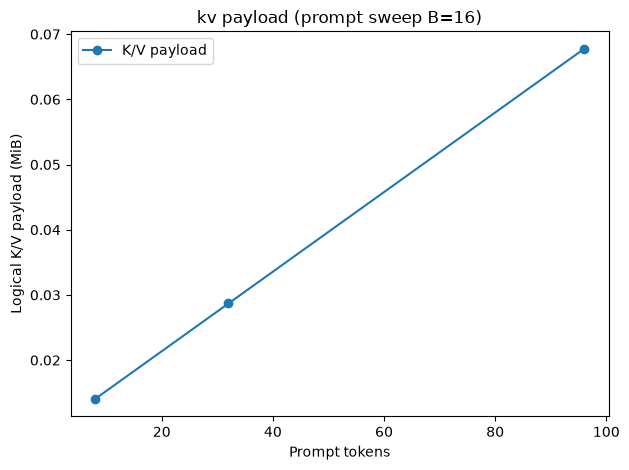

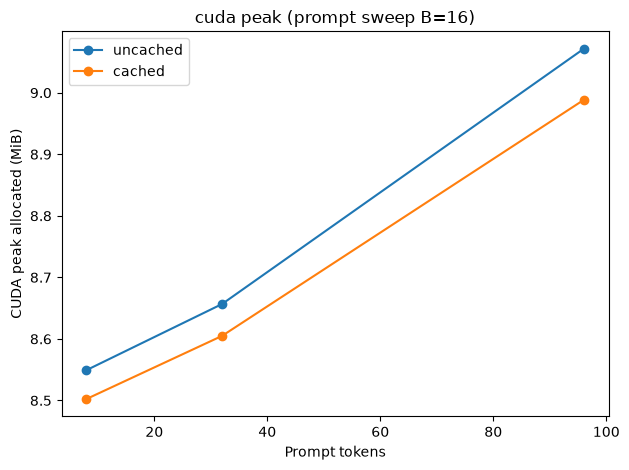

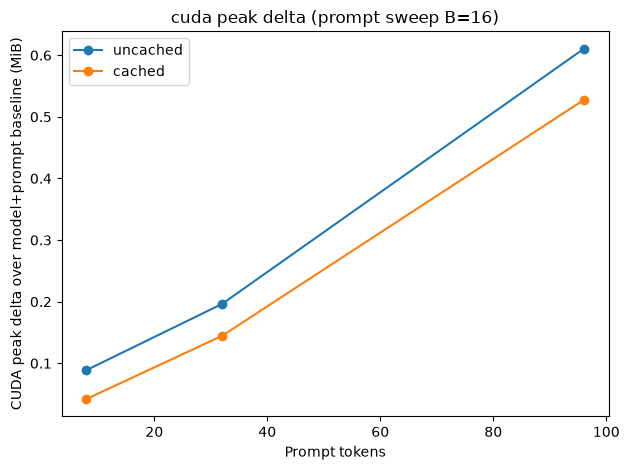

In [ ]:
"""Chạy sweep bounded mặc định, lưu JSON/CSV và SVG vào run directory mới."""
import torch
from IPython.display import Markdown, display

result = run_benchmark(config)
run_dir = save_results(result, ROOT / 'llm_foundations/experiments/kv_cache_benchmark_runs')
figures = plot_results(result, output_dir=run_dir / 'graphs')
print('Run:', run_dir)
print('Device:', result['environment']['device'], '| GPU:', result['environment']['gpu'])
print('Warmup/repeats:', config.warmup, '/', config.repeats)
print('Parameter mapping count:', result['mapping']['count'], '| correctness:', all(x.get('allclose') is not False for x in result['correctness']))
print('Source revision and hashes:', json.dumps(result['environment']['source'], indent=2))
print('Observed:', result['observations_vi'])

prompt_prefill_uncached


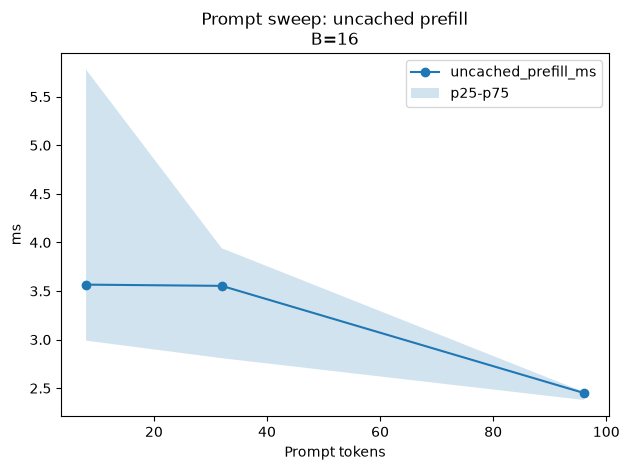

prompt_prefill_cached


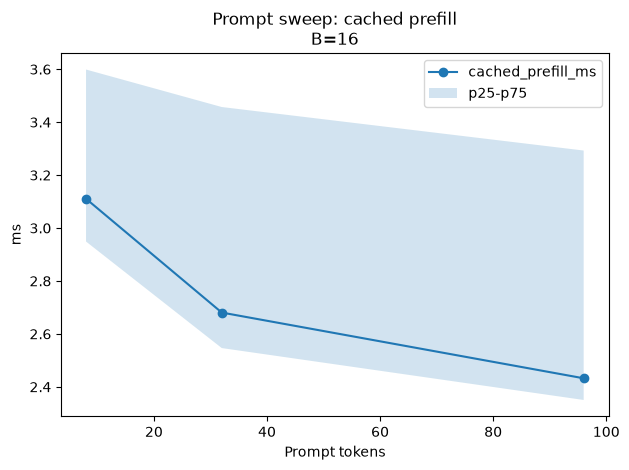

prompt_decode_uncached


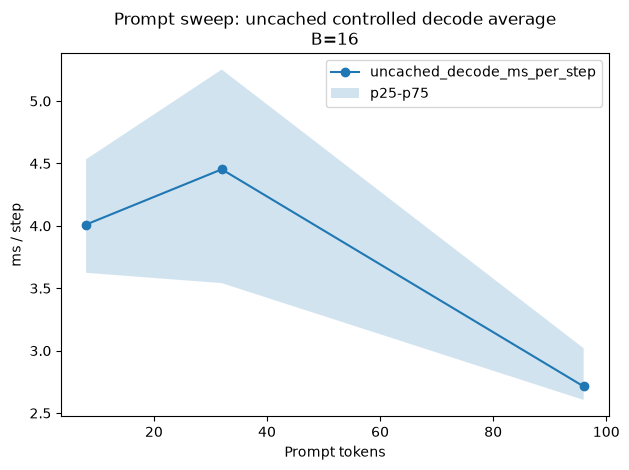

prompt_decode_cached


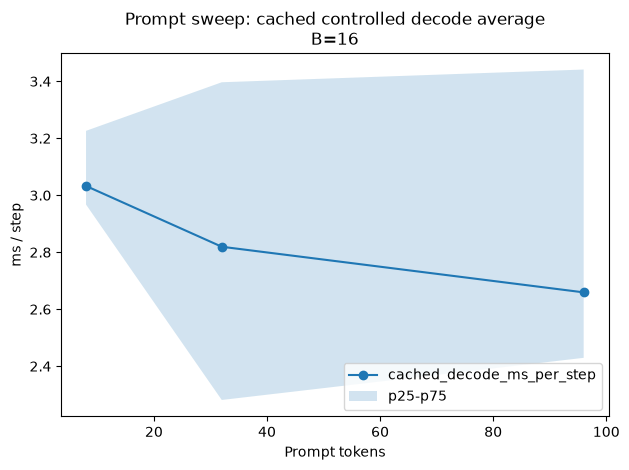

prompt_generation_uncached


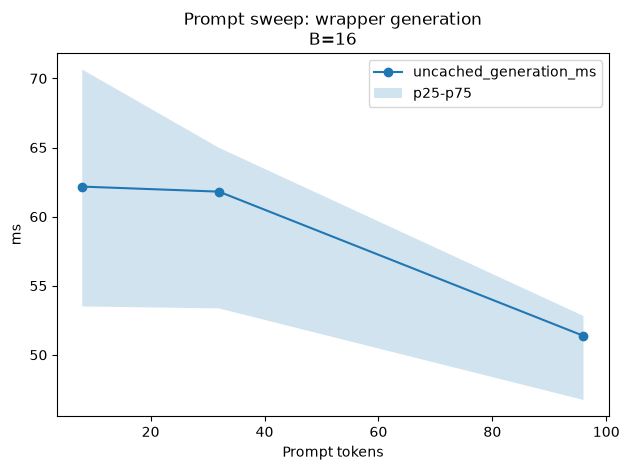

prompt_generation_cached


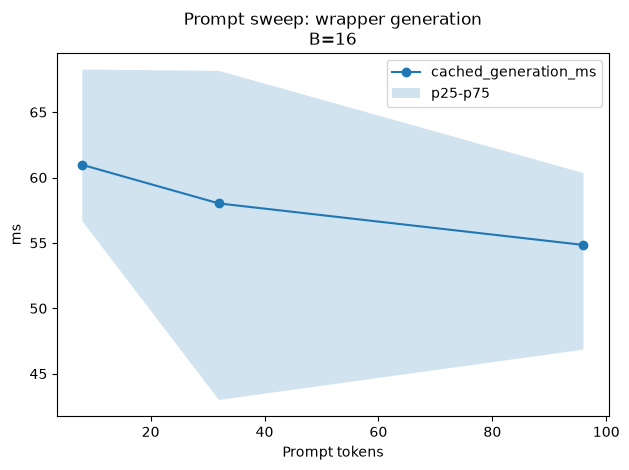

prompt_speedup


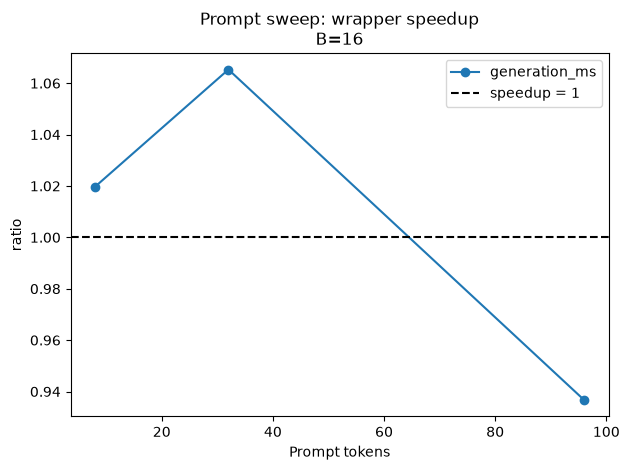

budget_generation_uncached


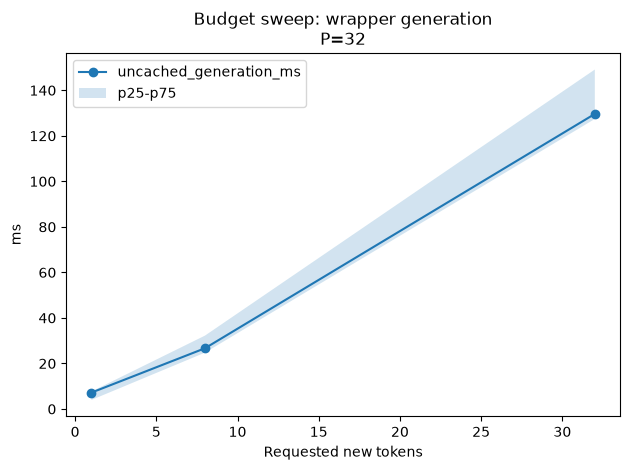

budget_generation_cached


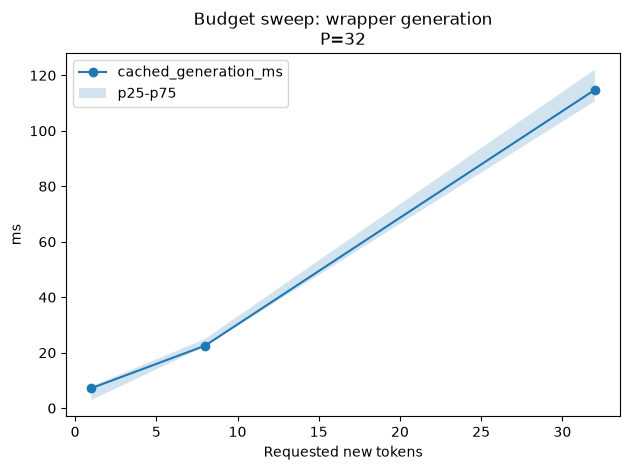

budget_speedup


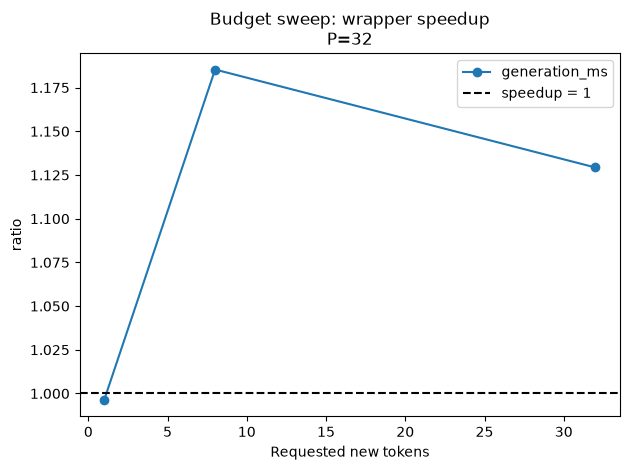

prompt_throughput_uncached


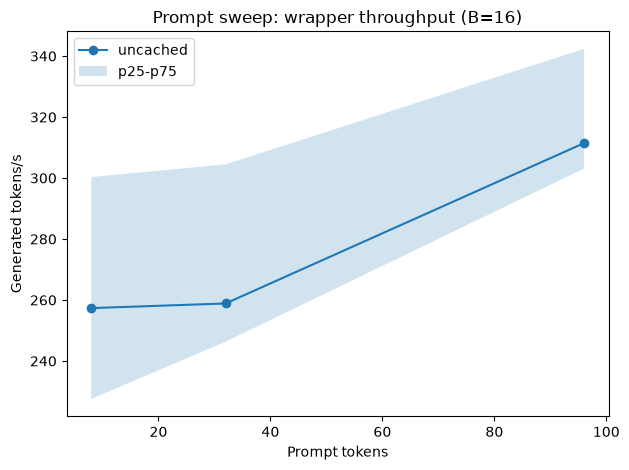

prompt_throughput_cached


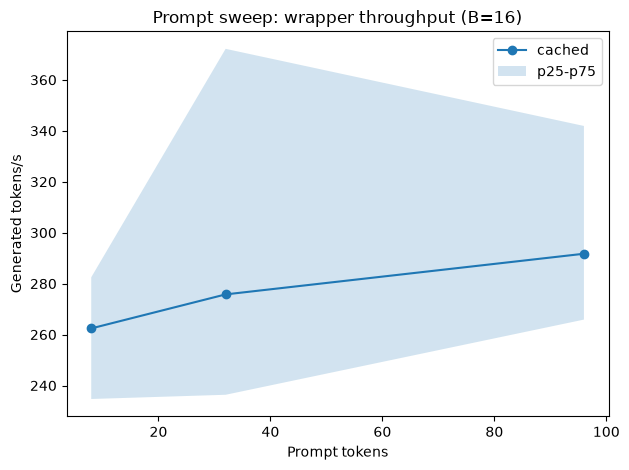

kv_payload


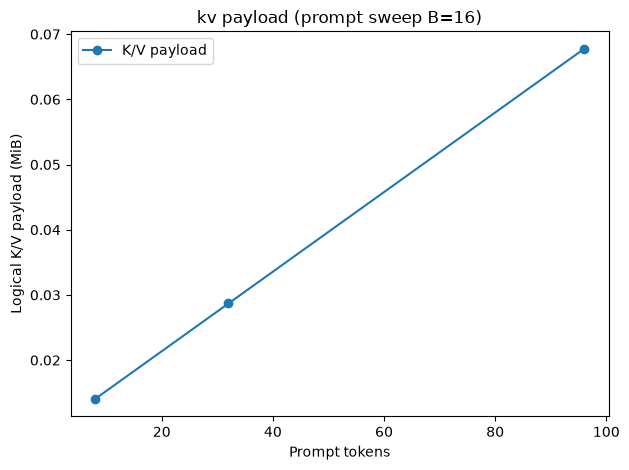

cuda_peak


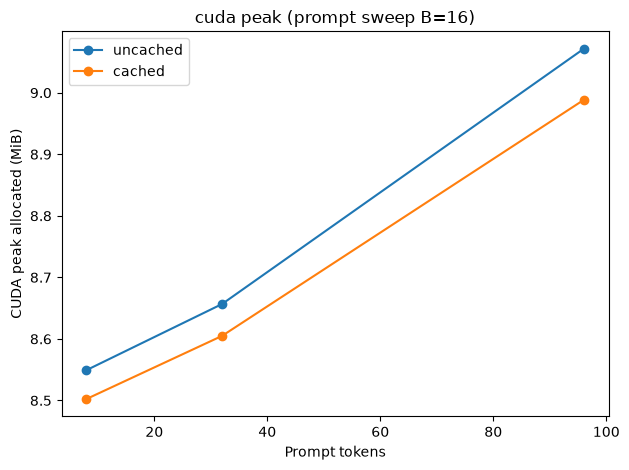

cuda_peak_delta


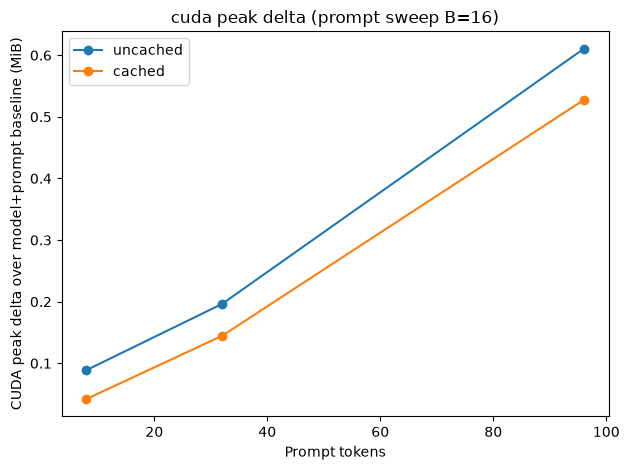

prompt-p8-b16 sweep= prompt P= 8 B= 16 N= 16 decode steps= 15 IDs agree= True
  speedups (ratio of medians): {'prefill_ms': 1.1463197747205263, 'decode_total_ms': 1.3223938419913233, 'generation_ms': 1.0197060831186768}
  cache payload MiB: 0.0140380859375 | cached peak/delta MiB: 8.50244140625 0.0419921875
prompt-p32-b16 sweep= prompt P= 32 B= 16 N= 16 decode steps= 15 IDs agree= True
  speedups (ratio of medians): {'prefill_ms': 1.3254007502798284, 'decode_total_ms': 1.5794119755006308, 'generation_ms': 1.0653156967472903}
  cache payload MiB: 0.0286865234375 | cached peak/delta MiB: 8.60498046875 0.14453125
prompt-p96-b16 sweep= prompt P= 96 B= 16 N= 16 decode steps= 15 IDs agree= True
  speedups (ratio of medians): {'prefill_ms': 1.0077415020066873, 'decode_total_ms': 1.0203450098533435, 'generation_ms': 0.9367171674983741}
  cache payload MiB: 0.0677490234375 | cached peak/delta MiB: 8.98828125 0.52734375
budget-p32-b1 sweep= budget P= 32 B= 1 N= 1 decode steps= 0 IDs agree= True


### Diễn giải: Trong prompt sweep đã đo, median speedup ratio-of-medians của wrapper cache là 1.020x (cache nhanh hơn); đây là mô hình chưa huấn luyện, chỉ mô tả workload nhỏ này và không đại diện chất lượng hay production. `kv_mib` là kích thước tensor K/V logic tại T=P+D, không phải tổng memory. `peak_allocated_mib` và `peak_delta_mib` đo live tensor allocation của allocator trong lượt generation cô lập; chúng không được cộng với payload. B=1 không có decode step nên decode là N/A, không phải 0. ID agreement chỉ mô tả greedy output của hai model đã matched trong workload này.

In [3]:
"""Hiển thị các figure từ samples đã lưu và tóm tắt đúng từng workload."""
for name, figure in figures.items():
    print(name)
    display(figure)
for case in result['cases']:
    print(case['case_id'], 'sweep=', case['sweep'], 'P=', case['prompt_length'], 'B=', case['requested_tokens'], 'N=', case['actual_tokens'], 'decode steps=', case['decode_steps'], 'IDs agree=', case['generation_ids_agree'])
    print('  speedups (ratio of medians):', case['speedups'])
    print('  cache payload MiB:', case['cache']['kv_mib'], '| cached peak/delta MiB:', case['memory']['cached']['peak_allocated_mib'], case['memory']['cached']['peak_delta_mib'])
display(Markdown('### Diễn giải: ' + result['observations_vi'] + ' `kv_mib` là kích thước tensor K/V logic tại T=P+D, không phải tổng memory. `peak_allocated_mib` và `peak_delta_mib` đo live tensor allocation của allocator trong lượt generation cô lập; chúng không được cộng với payload. B=1 không có decode step nên decode là N/A, không phải 0. ID agreement chỉ mô tả greedy output của hai model đã matched trong workload này.'))

Ở P=32, controlled decode có lợi rõ hơn trong lần đo này, nhưng toàn wrapper chỉ nhanh khoảng 1,065x. Điều này phù hợp với khả năng chi phí ngoài phần tính toán được itết kiệm đang đáng kể.

Với model cố định, dung lượng K/V đang tăng tuyến tính:

$$bytes=L× H× T_{cache}×(dₖ+dᵥ)×bytes/phần tử$$
Một nguyên nhân ta sẽ cần cô lập đó là: Cache lớn hơn cần đọc nhiều dữ liệu hơn; cách torch.cat hiện tại cũng có chi phí sao chép

# Kết luận
Trong workload nhỏ này, hai wrapper sinh cùng IDs. Cached giảm thời gian controlled decode ở một số case, nhưng lợi ích end-to-end nhỏ và không đồng đều; tại P=96 cached còn chậm hơn. K/V tăng tuyến tính theo số vị trí được xử lý. Chưa xác định nguyên nhân của khác biệt thời gian và độ dao động.